# Task 19: Hyperparameter Experimentation

## 1. Model parameters and hyperparameters

## 2. Load the dataset and prepare a fixed split

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Dataset shape: {X.shape}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Species: {list(iris.target_names)}")
X.head()

Dataset shape: (150, 4)
Training samples: 120
Testing samples: 30
Species: ['setosa', 'versicolor', 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 3. Run controlled hyperparameter experiments

In [5]:
BASELINE = {
    "n_estimators": 100,
    "max_depth": None,
    "min_samples_split": 2,
    "max_features": "sqrt",
}

experiments = {
    "n_estimators": [10, 50, 100, 200],
    "max_depth": [1, 2, 3, 5, None],
    "min_samples_split": [2, 5, 10, 20],
    "max_features": ["sqrt", 2, 3, 4],
}

results = []
for parameter, values in experiments.items():
    for value in values:
        settings = BASELINE.copy()
        settings[parameter] = value
        model = RandomForestClassifier(**settings, random_state=42)
        model.fit(X_train, y_train)
        results.append(
            {
                "Hyperparameter": parameter,
                "Value": str(value),
                "Train accuracy": model.score(X_train, y_train),
                "Test accuracy": model.score(X_test, y_test),
            }
        )

results_df = pd.DataFrame(results)
results_df

,Hyperparameter,Value,Train accuracy,Test accuracy
0,n_estimators,10,1.000000,0.966667
1,n_estimators,50,1.000000,0.900000
2,n_estimators,100,1.000000,0.900000
3,n_estimators,200,1.000000,0.900000
4,max_depth,1,0.966667,0.966667
5,max_depth,2,0.975000,0.900000
6,max_depth,3,0.983333,0.966667
7,max_depth,5,1.000000,0.933333
8,max_depth,None,1.000000,0.900000
9,min_samples_split,2,1.000000,0.900000


## 4. Compare test accuracy

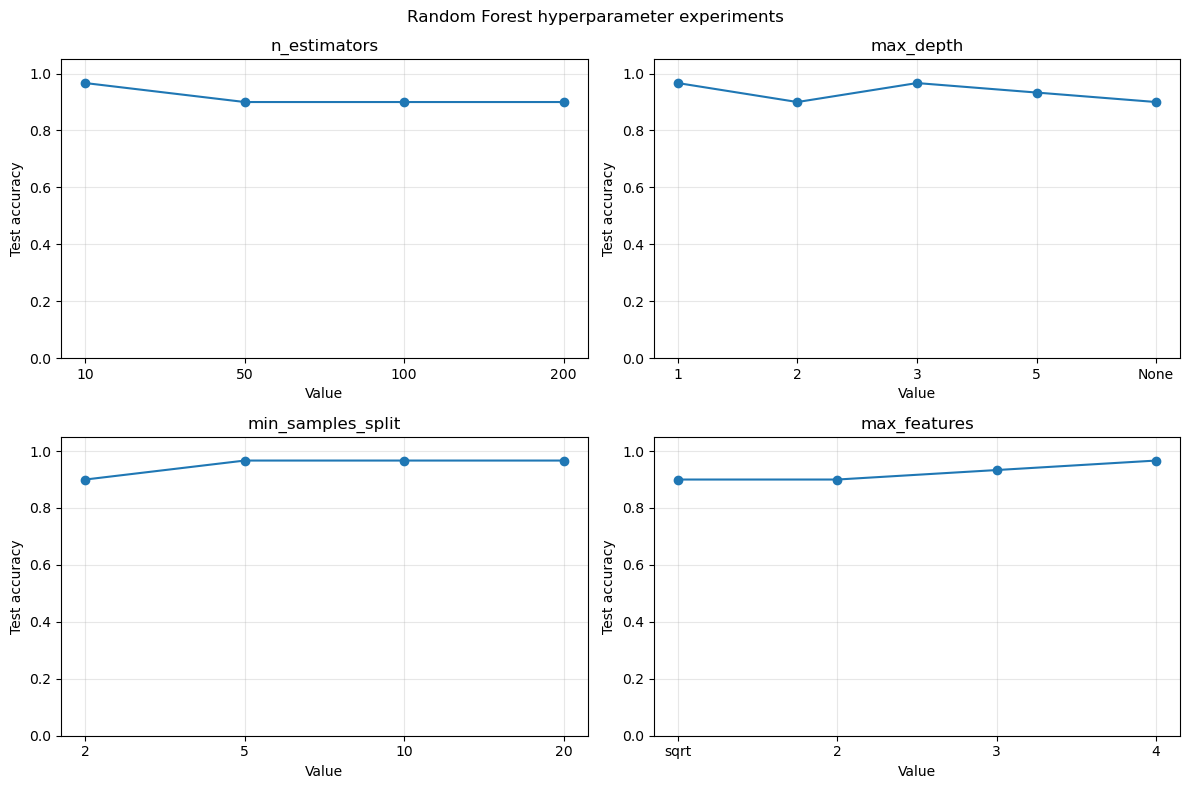

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, parameter in zip(axes.flat, experiments):
    subset = results_df[results_df["Hyperparameter"] == parameter]
    ax.plot(subset["Value"], subset["Test accuracy"], marker="o")
    ax.set_title(parameter)
    ax.set_xlabel("Value")
    ax.set_ylabel("Test accuracy")
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)

fig.suptitle("Random Forest hyperparameter experiments")
fig.tight_layout()
plt.show()